در این مرحله، فایل‌های ترین و تست ذخیره‌شده در دفترچه آماده‌سازی داده‌ها را بارگذاری می‌کنیم. ستون‌های زمان و قیمت پایانی را برای پیگیری مشاهدات نگه می‌داریم، اما از آن‌ها به‌عنوان ورودی مدل استفاده نمی‌کنیم. متغیر هدف نیز از ویژگی‌ها جدا می‌شود تا مدل فقط با ویژگی‌های تعیین‌شده آموزش ببیند.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, RocCurveDisplay
from sklearn.model_selection import TimeSeriesSplit, cross_val_score


In [4]:
train_data = pd.read_csv("btc_train.csv", parse_dates=["time"])
test_data = pd.read_csv("btc_test.csv", parse_dates=["time"])

feature_columns = [
    "return_1", "return_2", "return_3", "return_6",
    "candle_range", "close_open", "volume_change",
    "rsi_14", "macd", "macd_signal", "macd_diff",
    "bb_width", "bb_position", "atr_14"
]

X_train = train_data[feature_columns]
y_train = train_data["target"]
X_test = test_data[feature_columns]
y_test = test_data["target"]

print(X_train.shape, X_test.shape)
print(y_train.value_counts(normalize=True).sort_index())
print(y_test.value_counts(normalize=True).sort_index())


(8666, 14) (2167, 14)
target
0    0.502539
1    0.497461
Name: proportion, dtype: float64
target
0    0.492386
1    0.507614
Name: proportion, dtype: float64


متغیر هدف شامل دو دسته است: مقدار صفر یعنی قیمت پایانی کندل بعدی برابر یا کمتر از قیمت پایانی کندل فعلی باشد و مقدار یک یعنی قیمت پایانی کندل بعدی بیشتر باشد. از آنجا که برچسب‌های هدف برای داده‌های تاریخی مشخص هستند، مسئله را به‌صورت کلسیفیکیشن سوپروایزد باینری تعریف می‌کنیم. برای ارزیابی مدل‌ها، معیارهای اکیورسی، پریسیژن، ریکال هر دسته و اف۱ اسکور را گزارش می‌کنیم زیرا اکیورسی به‌تنهایی ممکن است عملکرد ضعیف مدل در تشخیص یکی از دسته‌ها را نشان ندهد.

در این مرحله، سه مدل لاجستیک رگرشن،  دسیژن تری و رندوم فارست را با یکدیگر مقایسه می‌کنیم. برای ارزیابی متقابل، از روشی استفاده می‌کنیم که در آن داده‌های هر بخش اعتبارسنجی از نظر زمانی پس از داده‌های آموزش همان بخش قرار دارند. این کار ترتیب زمانی داده‌ها را حفظ می‌کند و به ارزیابی واقع‌بینانه‌تر مدل‌ها کمک می‌کند.

In [5]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42)
}

time_split = TimeSeriesSplit(n_splits=5)
cv_results = []

for model_name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=time_split, scoring="accuracy")
    cv_results.append({
        "Model": model_name,
        "Mean CV Accuracy": scores.mean(),
        "CV Accuracy Std": scores.std()
    })

cv_results = pd.DataFrame(cv_results).sort_values("Mean CV Accuracy", ascending=False)
cv_results


,Model,Mean CV Accuracy,CV Accuracy Std
2,Random Forest,0.518421,0.003085
0,Logistic Regression,0.518144,0.010479
1,Decision Tree,0.517313,0.009891


پس از آموزش مدل‌ها، عملکرد آن‌ها را روی داده‌های آزمون که مربوط به بازه زمانی بعدی هستند بررسی می‌کنیم. به این ترتیب، مشخص می‌شود که مدل‌ها روی داده‌هایی که در مرحله آموزش ندیده‌اند، چگونه عمل می‌کنند.

In [9]:
majority_class = y_train.mode()[0]
baseline_predictions = np.full(len(y_test), majority_class)

results = []
trained_models = {}

for model_name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    trained_models[model_name] = model
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0)
    })

results.append({
    "Model": "Majority Class Baseline",
    "Accuracy": accuracy_score(y_test, baseline_predictions),
    "Precision": precision_score(y_test, baseline_predictions, zero_division=0),
    "Recall": recall_score(y_test, baseline_predictions, zero_division=0),
    "F1": f1_score(y_test, baseline_predictions, zero_division=0)
})

results = pd.DataFrame(results).sort_values("F1", ascending=False)
results


,Model,Accuracy,Precision,Recall,F1
2,Random Forest,0.522381,0.530806,0.509091,0.519722
0,Logistic Regression,0.511767,0.523230,0.430000,0.472056
1,Decision Tree,0.498846,0.511111,0.292727,0.372254
3,Majority Class Baseline,0.492386,0.000000,0.000000,0.000000


در این مرحله، جدول نتایج آزمون را بررسی می‌کنیم. در این تمرین، مدلی را انتخاب می‌کنیم که بالاترین اف۱ اسکور را دارد تا هم دقت پیش‌بینی‌های صعودی و هم میزان شناسایی درست این پیش‌بینی‌ها در نظر گرفته شوند.

In [10]:
best_model_name = results.iloc[0]["Model"]
if best_model_name == "Majority Class Baseline":
    best_predictions = baseline_predictions
else:
    best_model = trained_models[best_model_name]
    best_predictions = best_model.predict(X_test)

print("Selected model:", best_model_name)
print(results.iloc[0])

Selected model: Random Forest
Model        Random Forest
Accuracy          0.522381
Precision         0.530806
Recall            0.509091
F1                0.519722
Name: 2, dtype: object


در این مرحله، مدل انتخاب‌شده را بررسی می‌کنیم. کانفیوژن ماتریس نشان می‌دهد که چند نمونه از داده‌های آزمون به‌درستی یا به‌اشتباه در دسته‌های نزولی یا بدون تغییر و صعودی قرار گرفته‌اند. همچنین معیارهای اصلی ارزیابی مدل انتخاب‌شده را نمایش می‌دهیم. این نتایج فقط عملکرد مدل را در همین بازه زمانی آزمون توصیف می‌کنند.

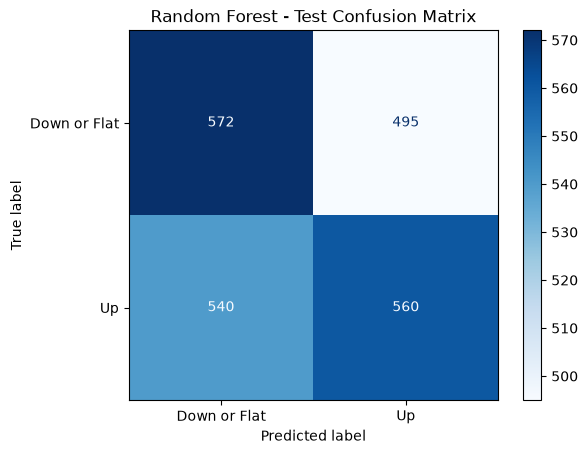

,Accuracy,Precision,Recall,F1
2,0.522381,0.530806,0.509091,0.519722


In [11]:
matrix = confusion_matrix(y_test, best_predictions)
display = ConfusionMatrixDisplay(confusion_matrix=matrix, display_labels=["Down or Flat", "Up"])
display.plot(cmap="Blues")
plt.title(best_model_name + " - Test Confusion Matrix")
plt.show()

selected_result = results[results["Model"] == best_model_name]
selected_result[["Accuracy", "Precision", "Recall", "F1"]]

کانفیوژن ماتریکس و جدول امتیازها، خلاصه‌ای از نتایج مدل انتخاب‌شده روی داده‌های آزمون ارائه می‌دهند. عملکرد خوب در این بازه زمانی به‌تنهایی تضمین نمی‌کند که مدل در آینده نیز عملکرد مشابهی داشته باشد.

In [12]:
print("Selected model:", best_model_name)
print("Test accuracy:", accuracy_score(y_test, best_predictions))
print("Test precision:", precision_score(y_test, best_predictions, zero_division=0))
print("Test recall:", recall_score(y_test, best_predictions, zero_division=0))
print("Test F1:", f1_score(y_test, best_predictions, zero_division=0))

Selected model: Random Forest
Test accuracy: 0.522381172127365
Test precision: 0.5308056872037915
Test recall: 0.509090909090909
Test F1: 0.5197215777262181


معیارهای ارزیابی همه مدل‌های مورد بررسی را در یک فایل CSV ذخیره می‌کنیم. پس از اجرای دفترچه، می‌توان از این فایل برای مرور و مقایسه نتایج مدل‌ها استفاده کرد.

In [ ]:
results.to_csv("btc_model_comparison.csv", index=False)
results

در این دفترچه، سه مدل دسته‌بندی را با استفاده از داده‌های آموزش مقایسه کردیم و پیش‌بینی‌های آن‌ها را روی یک بازه زمانی جدیدتر برای آزمون ارزیابی کردیم. جدول نتایج شامل یک مدل مبنا است که همیشه دسته پرتکرارتر را پیش‌بینی می‌کند و چند معیار ساده برای ارزیابی عملکرد مدل‌ها را نشان می‌دهد. کانفیوژن ماتریکس نیز جزئیات بیشتری درباره پیش‌بینی‌های مدل انتخاب‌شده ارائه می‌کند.